# LSTM과 GRU 셀

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"   # 데이터셋 로딩에만 keras 사용 (TensorFlow 불필요)

import random
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

import keras  # imdb 데이터 로딩 전용

### 재사용 함수 (이전 코드와 동일)

In [2]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')   # GPU PC / CPU 노트북 공용
print(device)

cpu


### keras pad_sequences 기본 동작(padding='pre', truncating='pre')과 동일

In [3]:
def pad_sequences(seqs, maxlen):
    out = np.zeros((len(seqs), maxlen), dtype=np.int64)
    for i, s in enumerate(seqs):
        s = s[-maxlen:]
        if len(s) > 0:
            out[i, -len(s):] = s
    return out

### 학습 유틸

In [4]:
def fit(model, train_x, train_y, val_x, val_y, ckpt_path,
        epochs=100, batch_size=64, lr=1e-4, patience=3):
    model.to(device)

    optimizer = torch.optim.RMSprop(model.parameters(), lr=lr)
    criterion = nn.BCEWithLogitsLoss()      # sigmoid + binary_crossentropy

    train_loader = DataLoader(TensorDataset(train_x, train_y), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(TensorDataset(val_x, val_y), batch_size=batch_size)

    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    best_val_loss, best_state, wait, stopped_epoch = float('inf'), None, 0, 0

    for epoch in range(epochs):
        # train
        model.train()
        total_loss, correct, n = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += ((logits > 0).float() == yb).sum().item()
            n += len(yb)
        history['loss'].append(total_loss / n)
        history['accuracy'].append(correct / n)

        # validation
        model.eval()
        total_loss, correct, n = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                total_loss += criterion(logits, yb).item() * len(yb)
                correct += ((logits > 0).float() == yb).sum().item()
                n += len(yb)
        val_loss = total_loss / n
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(correct / n)

        print(f"Epoch {epoch+1}/{epochs} - loss: {history['loss'][-1]:.4f} - acc: {history['accuracy'][-1]:.4f} "
              f"- val_loss: {val_loss:.4f} - val_acc: {history['val_accuracy'][-1]:.4f}")

        # ModelCheckpoint(save_best_only) + EarlyStopping(restore_best_weights)
        if val_loss < best_val_loss:
            best_val_loss, wait = val_loss, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save(best_state, ckpt_path)
        else:
            wait += 1
            if wait >= patience:
                stopped_epoch = epoch
                break

    model.load_state_dict(best_state)
    return history, stopped_epoch

def plot_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    axes[0].plot(history['accuracy'])
    axes[0].plot(history['val_accuracy'])
    axes[0].set_xlabel('epoch')
    axes[0].set_ylabel('accuracy')
    axes[0].legend(['train', 'val'])

    axes[1].plot(history['loss'])
    axes[1].plot(history['val_loss'])
    axes[1].set_xlabel('epoch')
    axes[1].set_ylabel('loss')
    axes[1].legend(['train', 'val'])

    plt.show()

def summary(model):
    print(model)
    print('params:', sum(p.numel() for p in model.parameters()))


### 데이터

In [5]:
(train_input, train_target), (test_input, test_target) = keras.datasets.imdb.load_data(num_words=500)
print(train_input.shape, train_target.shape)
print(test_input.shape, test_target.shape)

train_input, val_input, train_target, val_target = train_test_split(
    train_input, train_target, test_size=0.2, random_state=42
)
print(train_input.shape, train_target.shape)
print(val_input.shape, val_target.shape)

train_seq = pad_sequences(train_input, maxlen=100)
val_seq = pad_sequences(val_input, maxlen=100)
test_seq = pad_sequences(test_input, maxlen=100)
print(train_seq.shape, val_seq.shape)

train_x, val_x, test_x = map(torch.from_numpy, (train_seq, val_seq, test_seq))
train_y, val_y, test_y = (torch.from_numpy(t).float() for t in (train_target, val_target, test_target))

(25000,) (25000,)
(25000,) (25000,)
(20000,) (20000,)
(5000,) (5000,)
(20000, 100) (5000, 100)


### 모델

In [6]:
# [변경] LockedDropout 제거 -> nn.LSTM/GRU 의 dropout 인자 + nn.Dropout 사용
class RecurrentClassifier(nn.Module):
    def __init__(self, rnn_type='lstm', num_layers=1, dropout=0.0,
                 vocab_size=500, embed_dim=16, hidden=8):
        super().__init__()
        rnn_cls = {'lstm': nn.LSTM, 'gru': nn.GRU}[rnn_type]
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        # [변경] 층이 여러 개일 때는 num_layers 로 한 번에 쌓고, dropout 은 "층 사이"에만 적용됨
        #        (num_layers=1 이면 dropout 인자가 무시되며 경고가 나므로 0.0 으로 전달)
        self.rnn = rnn_cls(embed_dim, hidden, num_layers=num_layers, batch_first=True,
                           dropout=dropout if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)                  # [변경] RNN 출력에 적용하는 일반 dropout
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):                                   # x: (B, 100)
        x = self.embedding(x)                               # (B, 100, 16)
        _, h = self.rnn(x)                                  # [변경] 마지막 hidden state(h_n) 사용
        h = h[0] if isinstance(h, tuple) else h             # LSTM 은 (h_n, c_n) 반환, GRU 는 h_n
        h = h[-1]                                           # (B, 8) 마지막 층의 hidden
        return self.fc(self.dropout(h)).squeeze(-1)


def run(model, ckpt_path):
    summary(model)
    history, stopped_epoch = fit(model, train_x, train_y, val_x, val_y, ckpt_path=ckpt_path)
    print(stopped_epoch)
    plot_history(history)
    return history

### 1) LSTM

RecurrentClassifier(
  (embedding): Embedding(500, 16)
  (rnn): LSTM(16, 8, batch_first=True)
  (dropout): Dropout(p=0.0, inplace=False)
  (fc): Linear(in_features=8, out_features=1, bias=True)
)
params: 8841
Epoch 1/100 - loss: 0.6945 - acc: 0.5072 - val_loss: 0.6946 - val_acc: 0.4978
Epoch 2/100 - loss: 0.6927 - acc: 0.5127 - val_loss: 0.6930 - val_acc: 0.5056
Epoch 3/100 - loss: 0.6916 - acc: 0.5275 - val_loss: 0.6917 - val_acc: 0.5270
Epoch 4/100 - loss: 0.6907 - acc: 0.5402 - val_loss: 0.6906 - val_acc: 0.5414
Epoch 5/100 - loss: 0.6897 - acc: 0.5459 - val_loss: 0.6896 - val_acc: 0.5388
Epoch 6/100 - loss: 0.6886 - acc: 0.5469 - val_loss: 0.6885 - val_acc: 0.5374
Epoch 7/100 - loss: 0.6875 - acc: 0.5496 - val_loss: 0.6873 - val_acc: 0.5388
Epoch 8/100 - loss: 0.6863 - acc: 0.5497 - val_loss: 0.6862 - val_acc: 0.5430
Epoch 9/100 - loss: 0.6850 - acc: 0.5544 - val_loss: 0.6850 - val_acc: 0.5446
Epoch 10/100 - loss: 0.6835 - acc: 0.5578 - val_loss: 0.6836 - val_acc: 0.5476
Epoch 11/1

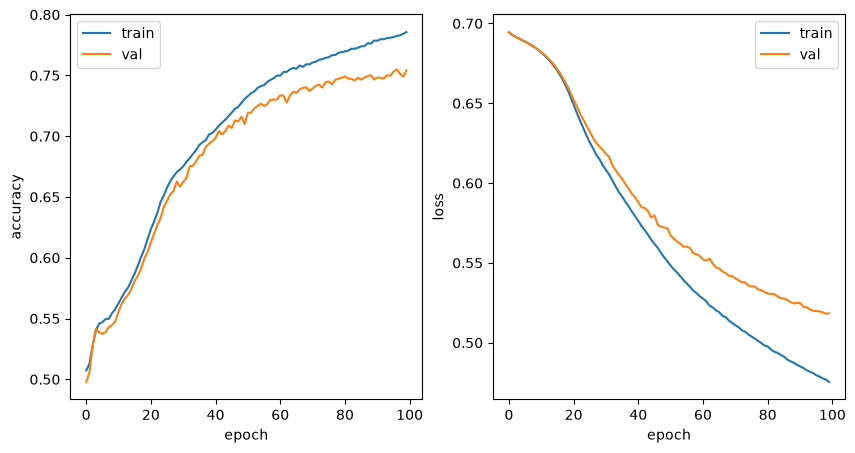

{'loss': [0.6944848956108093,
  0.6927431276321411,
  0.6916496698379516,
  0.6906578477859497,
  0.6896754062652588,
  0.6886490650177002,
  0.6875315654754639,
  0.6863234586715699,
  0.6849711285591126,
  0.6834730597496033,
  0.6818191296577454,
  0.6799624401092529,
  0.6779199632644654,
  0.6756514640808106,
  0.6731180994987488,
  0.670241479587555,
  0.6670020118713379,
  0.6632942747116088,
  0.6591004239082336,
  0.6542846786499024,
  0.6491575561523437,
  0.6439830865859986,
  0.6390898929595947,
  0.6344292861938476,
  0.6297052710533142,
  0.6254464537620544,
  0.6218369969367981,
  0.6176597210884094,
  0.6150203715324402,
  0.6111580863952637,
  0.6082806986808776,
  0.605297918510437,
  0.6016010933876038,
  0.5979212507247925,
  0.5942384132385254,
  0.5915946370124817,
  0.5882949595928192,
  0.585383397102356,
  0.5822238930702209,
  0.5792875053405762,
  0.5762348610877991,
  0.5731079162597656,
  0.5704638360977173,
  0.5676624784469605,
  0.5646150559425354,
  0.5

In [7]:
model_lstm = RecurrentClassifier('lstm')        # PyTorch LSTM: (16*8 + 8*8 + 8*2) * 4 = 832 (bias 2개)
run(model_lstm, './best-lstm-model.pt')

### 2) LSTM + dropout

RecurrentClassifier(
  (embedding): Embedding(500, 16)
  (rnn): LSTM(16, 8, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=8, out_features=1, bias=True)
)
params: 8841
Epoch 1/100 - loss: 0.6944 - acc: 0.5062 - val_loss: 0.6924 - val_acc: 0.5146
Epoch 2/100 - loss: 0.6936 - acc: 0.5107 - val_loss: 0.6918 - val_acc: 0.5188
Epoch 3/100 - loss: 0.6928 - acc: 0.5181 - val_loss: 0.6912 - val_acc: 0.5274
Epoch 4/100 - loss: 0.6919 - acc: 0.5231 - val_loss: 0.6906 - val_acc: 0.5274
Epoch 5/100 - loss: 0.6921 - acc: 0.5209 - val_loss: 0.6900 - val_acc: 0.5302
Epoch 6/100 - loss: 0.6909 - acc: 0.5264 - val_loss: 0.6894 - val_acc: 0.5314
Epoch 7/100 - loss: 0.6905 - acc: 0.5300 - val_loss: 0.6889 - val_acc: 0.5338
Epoch 8/100 - loss: 0.6895 - acc: 0.5363 - val_loss: 0.6883 - val_acc: 0.5332
Epoch 9/100 - loss: 0.6894 - acc: 0.5331 - val_loss: 0.6877 - val_acc: 0.5376
Epoch 10/100 - loss: 0.6878 - acc: 0.5426 - val_loss: 0.6871 - val_acc: 0.5418
Epoch 11/1

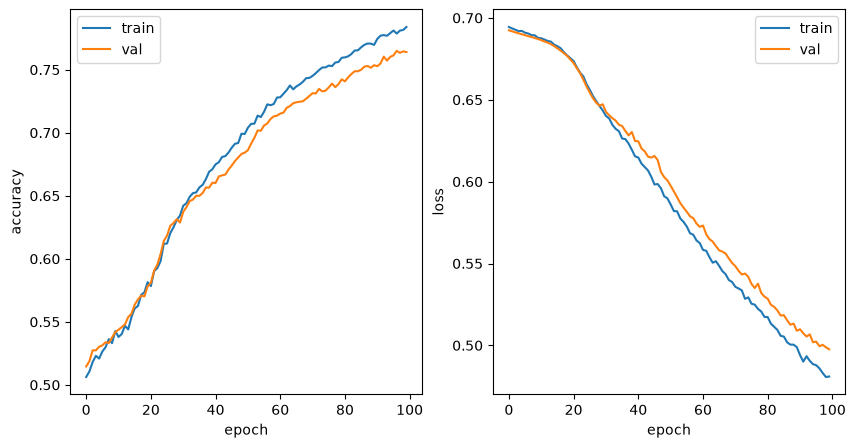

{'loss': [0.6944477801322937,
  0.6935621315002442,
  0.6927807878494263,
  0.6919136284828186,
  0.6920582014083863,
  0.6909461193084717,
  0.6904611784934997,
  0.6894538294792175,
  0.6893621026992798,
  0.6877831092834472,
  0.6875431635856628,
  0.6867602552413941,
  0.6859295486450195,
  0.6854806903839111,
  0.6836296008110047,
  0.682716231918335,
  0.6814650394439697,
  0.6790624824523925,
  0.6770906908988953,
  0.675414169216156,
  0.6736288001060485,
  0.669838437461853,
  0.666564758682251,
  0.6642866135597228,
  0.6595796889305114,
  0.6560904598236084,
  0.6522234424591065,
  0.6491269983291627,
  0.646241375541687,
  0.6435008178710937,
  0.6401508416175842,
  0.6386299208641052,
  0.6346798758506775,
  0.6322254556655884,
  0.6308381820678711,
  0.6263711289405822,
  0.6259792652130127,
  0.6232822342872619,
  0.6194736481666565,
  0.6154568180084229,
  0.6147367473125458,
  0.6109803713798523,
  0.6089034255981445,
  0.6068419216156006,
  0.6030269757270813,
  0.598

In [8]:
model_dropout = RecurrentClassifier('lstm', dropout=0.3)
run(model_dropout, './best-dropout-model.pt')

### 3) 2층 LSTM + dropout

RecurrentClassifier(
  (embedding): Embedding(500, 16)
  (rnn): LSTM(16, 8, num_layers=2, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=8, out_features=1, bias=True)
)
params: 9417
Epoch 1/100 - loss: 0.6949 - acc: 0.4967 - val_loss: 0.6928 - val_acc: 0.5126
Epoch 2/100 - loss: 0.6937 - acc: 0.5005 - val_loss: 0.6924 - val_acc: 0.5128
Epoch 3/100 - loss: 0.6928 - acc: 0.5096 - val_loss: 0.6922 - val_acc: 0.5270
Epoch 4/100 - loss: 0.6919 - acc: 0.5192 - val_loss: 0.6918 - val_acc: 0.5378
Epoch 5/100 - loss: 0.6914 - acc: 0.5291 - val_loss: 0.6912 - val_acc: 0.5416
Epoch 6/100 - loss: 0.6906 - acc: 0.5352 - val_loss: 0.6901 - val_acc: 0.5508
Epoch 7/100 - loss: 0.6892 - acc: 0.5482 - val_loss: 0.6887 - val_acc: 0.5602
Epoch 8/100 - loss: 0.6878 - acc: 0.5556 - val_loss: 0.6869 - val_acc: 0.5618
Epoch 9/100 - loss: 0.6848 - acc: 0.5659 - val_loss: 0.6844 - val_acc: 0.5676
Epoch 10/100 - loss: 0.6831 - acc: 0.5659 - val_loss: 0.6814 -

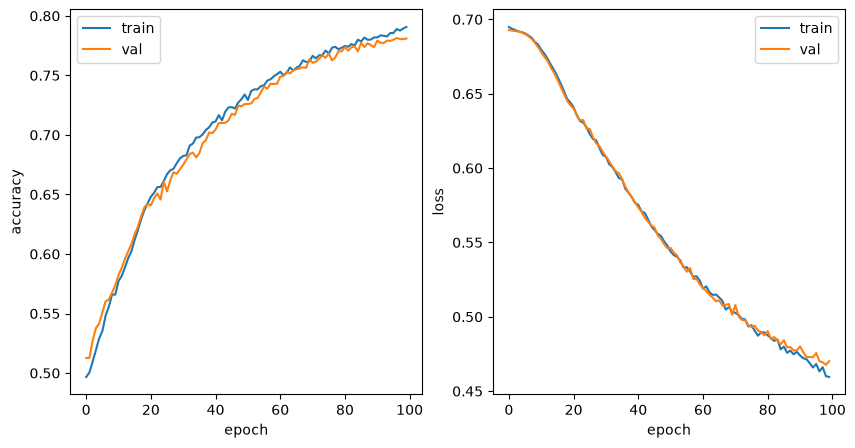

{'loss': [0.6948813736915589,
  0.6936691657066345,
  0.692787922668457,
  0.6919142769813538,
  0.6914106474876404,
  0.690579831981659,
  0.689237201499939,
  0.6877722296714782,
  0.6848129643440246,
  0.6831459586143493,
  0.6795889739990234,
  0.6767808568954468,
  0.673371194267273,
  0.669421675491333,
  0.6657800008773803,
  0.6615888605117798,
  0.6568334375381469,
  0.6518911047935486,
  0.6465092928886413,
  0.6441208346366882,
  0.6408694251060486,
  0.635593022441864,
  0.6316126353263855,
  0.6305630403518677,
  0.6273862689971924,
  0.6228590584754944,
  0.6195130579948426,
  0.618662467956543,
  0.613384126663208,
  0.6088350224494934,
  0.6076387578964233,
  0.6025949388504028,
  0.6007171913146973,
  0.5972227127075195,
  0.5933046270370483,
  0.592403408908844,
  0.5860115604400635,
  0.5833709330558777,
  0.5804154777526855,
  0.5765800422668457,
  0.5752400242805481,
  0.5708312758445739,
  0.5698006457328796,
  0.5654493663787842,
  0.5610179857254028,
  0.5583862

In [9]:
model_lstm_2 = RecurrentClassifier('lstm', num_layers=2, dropout=0.3)   # 832 + 576
run(model_lstm_2, './best-2rnn-model.pt')

### 4) GRU

RecurrentClassifier(
  (embedding): Embedding(500, 16)
  (rnn): GRU(16, 8, batch_first=True)
  (dropout): Dropout(p=0.0, inplace=False)
  (fc): Linear(in_features=8, out_features=1, bias=True)
)
params: 8633
Epoch 1/100 - loss: 0.7018 - acc: 0.4991 - val_loss: 0.6924 - val_acc: 0.5294
Epoch 2/100 - loss: 0.6944 - acc: 0.5119 - val_loss: 0.6904 - val_acc: 0.5358
Epoch 3/100 - loss: 0.6920 - acc: 0.5217 - val_loss: 0.6894 - val_acc: 0.5338
Epoch 4/100 - loss: 0.6905 - acc: 0.5270 - val_loss: 0.6885 - val_acc: 0.5394
Epoch 5/100 - loss: 0.6891 - acc: 0.5326 - val_loss: 0.6874 - val_acc: 0.5418
Epoch 6/100 - loss: 0.6879 - acc: 0.5385 - val_loss: 0.6865 - val_acc: 0.5476
Epoch 7/100 - loss: 0.6866 - acc: 0.5470 - val_loss: 0.6854 - val_acc: 0.5528
Epoch 8/100 - loss: 0.6852 - acc: 0.5525 - val_loss: 0.6843 - val_acc: 0.5558
Epoch 9/100 - loss: 0.6838 - acc: 0.5572 - val_loss: 0.6832 - val_acc: 0.5594
Epoch 10/100 - loss: 0.6823 - acc: 0.5623 - val_loss: 0.6819 - val_acc: 0.5660
Epoch 11/10

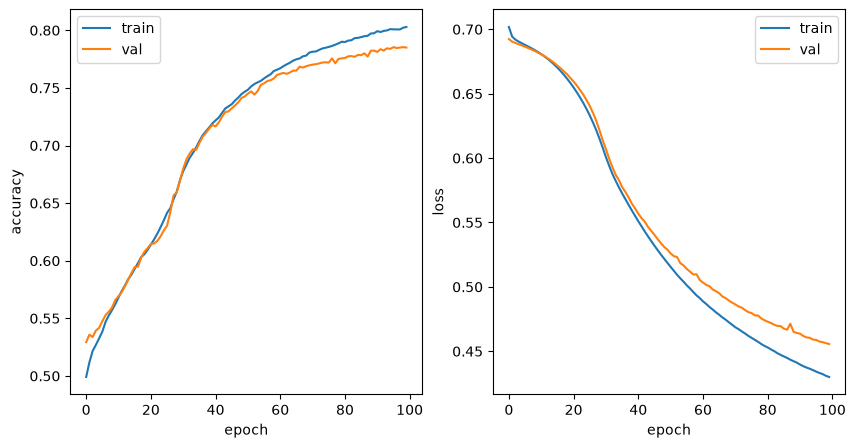

{'loss': [0.70179419298172,
  0.6943637668609619,
  0.6919996228218078,
  0.6904861204147339,
  0.6891465608596802,
  0.6878688111305237,
  0.6865731265068055,
  0.6852429718971252,
  0.6838453325271606,
  0.6823401829719543,
  0.6807179146766663,
  0.678946856212616,
  0.6770209428787232,
  0.6749223064422607,
  0.6726624710083008,
  0.6701978050231934,
  0.6675615481376648,
  0.664695569229126,
  0.6616177429199219,
  0.6583401230812073,
  0.6548280915260315,
  0.6510727684020996,
  0.6470499804496765,
  0.6427869282722473,
  0.6381237285614013,
  0.6330704840660095,
  0.6275968360900879,
  0.6216980251312256,
  0.6151208567619324,
  0.6080895117759705,
  0.6006796433448791,
  0.5940300688743592,
  0.5876706028938293,
  0.5823978598117828,
  0.5773176670074462,
  0.5726216524124146,
  0.5681882495880127,
  0.5636843990325928,
  0.5593511965751647,
  0.5551559182167053,
  0.5509554636955262,
  0.5470462594032287,
  0.5430343091011047,
  0.5392481944084168,
  0.5355968288421631,
  0.53

In [10]:
model_gru = RecurrentClassifier('gru')          # 624 = (8*16 + 8*8 + 8*2) * 3 (Keras와 동일)
run(model_gru, './best-gru-model.pt')

### 테스트 평가

In [11]:
def evaluate(model, x, y, batch_size=64):
    model.to(device).eval()
    criterion = nn.BCEWithLogitsLoss()
    loader = DataLoader(TensorDataset(x, y), batch_size=batch_size)
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            total_loss += criterion(logits, yb).item() * len(yb)
            correct += ((logits > 0).float() == yb).sum().item()
    loss, acc = total_loss / len(y), correct / len(y)
    print(f'loss: {loss:.4f} - accuracy: {acc:.4f}')
    return loss, acc

best_2rnn_model = RecurrentClassifier('lstm', num_layers=2, dropout=0.3)
best_2rnn_model.load_state_dict(torch.load('./best-2rnn-model.pt', map_location=device))
evaluate(best_2rnn_model, test_x, test_y)

loss: 0.4640 - accuracy: 0.7827


(0.4639684221839905, 0.78272)